# 04.1 - Carrier-window sandbox

A playground for the windowed carrier-channel statistic, built to be taken apart. Everything
is generated from the phase pair, so parameters can be changed without touching `data/`.

The interlaced checkerboard puts $\Delta\varphi$ on a carrier at the **scan Nyquist**
frequency, far outside the sample's own bandwidth $2k_{\rm cut}$. Nothing the sample does
unaided can reach that part of scan-frequency space, so the carrier channel should be empty
except for the excitation. This notebook looks at one window's partial Fourier transform
there, scores it, and then scans that score over the field.

## Two things that will silently ruin the result

**1. Use an EVEN number of scan positions per window.** The window's DFT bins sit at
$p/(W\Delta)$ and the carrier is at $1/(2\Delta)$, i.e. $p = W/2$. For even $W$ that is an
integer and the carrier is exactly the Nyquist bin; for odd $W$ it falls *between* bins.
Measured 2026-11-02: signal-to-null ratio **1.41 for W=51** against **1273 for W=50** -
same data, same everything else. An odd window makes the statistic mostly leaked lattice.

**2. Consider apodising.** A box window's sinc sidelobes fall only as $1/\Delta q$, so the
lattice at $|q| \le 1.233\ \AA^{-1}$ leaks into the carrier at $5.0\ \AA^{-1}$. A Hann taper
takes the signal-to-null ratio to $\sim\!1.4\times10^5$ regardless of parity - but it also
halves the coherent gain, so a Hann window of width $W$ only covers $\sim\!W/2$ effectively.
Compare tapers at matched *effective* width, not matched nominal width.

**Always run the NULL.** Build the same map from base-interlaced-with-base (no excitation
anywhere). If it is not featureless, the statistic is reading the lattice, not the signal.

In [1]:
%load_ext autoreload
%autoreload 2

import pickle
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve

sys.path.insert(0, str(Path.cwd().parent))        # scripts/ holds stem_utils
from stem_utils import generate_datacube

# ---- acquisition -----------------------------------------------------------
ACC_VOLTAGE     = 60e3    # eV
PROBE_SEMIANGLE = 30      # mrad
PROBE_DEFOCUS   = 0       # A   (C10 = 0, the focus0 convention)
SCAN_STEP       = 0.1     # A   oversampled ~4x vs the 0.406 A alias-free step, which is
                          #     what leaves the carrier sitting in empty frequency space
DOSE            = 1e6     # e/A^2, or None for noiseless

# ---- window ----------------------------------------------------------------
W      = 50               # MUST BE EVEN - see the header
TAPER  = "box"            # "box" or "hann"
NB     = 1                # +-NB frequency bins around the carrier -> (2NB+1)^2 bins
assert W % 2 == 0, "odd W puts the carrier between DFT bins; see the header"

LAMBDA  = 12.398 / np.sqrt(ACC_VOLTAGE*1e-3 * (2*511 + ACC_VOLTAGE*1e-3)) # A
K_CUT   = (PROBE_SEMIANGLE * 1e-3) / LAMBDA
Q_NYQ   = 0.5 / SCAN_STEP
print(f"lambda {LAMBDA:.4f} A | sample bandwidth 2k_cut = {2*K_CUT:.3f} 1/A")
print(f"scan Nyquist (the carrier) = {Q_NYQ:.3f} 1/A  -> {Q_NYQ/(2*K_CUT):.2f}x outside it")
print(f"window {W} positions = {W*SCAN_STEP:.1f} A, taper {TAPER!r}, {(2*NB+1)**2} bins")

lambda 0.0487 A | sample bandwidth 2k_cut = 1.233 1/A
scan Nyquist (the carrier) = 5.000 1/A  -> 4.05x outside it
window 50 positions = 5.0 A, taper 'box', 9 bins


## 1 - The phase data

`base` is light-off, `excited` is light-on; the difference is what we are trying to find.
Note the scale: the excitation peaks around 0.021 rad on a base phase that swings 0.23 rad,
so it is a ~2 % perturbation on something that is itself hard to see.

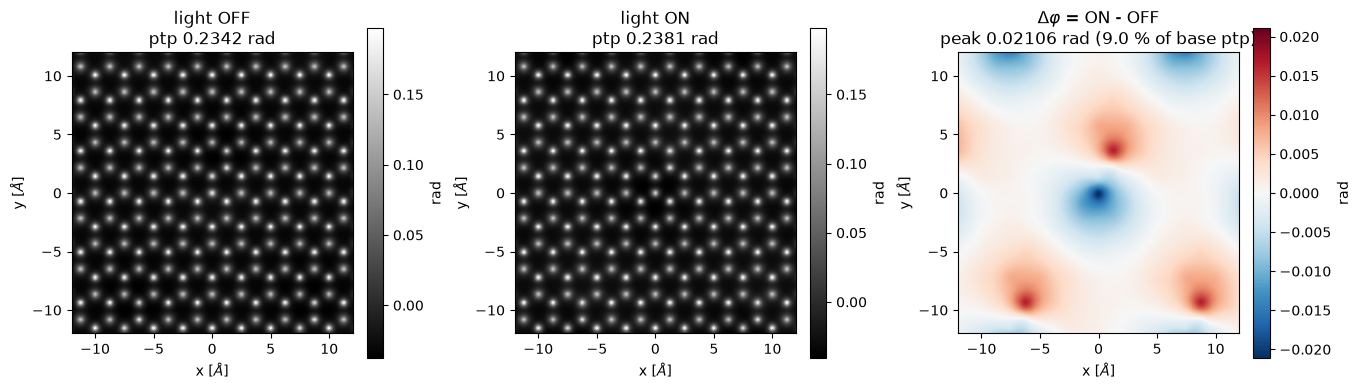

excitation centroid (|dphi|-weighted): (+0.138, -0.023) A


In [2]:
PHASE_PKL = Path.cwd().parent / "hbn_bcenters_data" / "bcenters_base_excited_phases_wide_fov.pkl"
with open(PHASE_PKL, "rb") as fh:
    data = pickle.load(fh)

phase_base = np.asarray(data["base"], dtype=np.float64)
phase_exc  = np.asarray(data["excited"], dtype=np.float64)
x, y       = np.asarray(data["x"]), np.asarray(data["y"])
delta_phi  = phase_exc - phase_base
extent     = [x[0], x[-1], y[0], y[-1]]

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2), constrained_layout=True)
for ax, img, title in (
    (axes[0], phase_base, "light OFF"),
    (axes[1], phase_exc,  "light ON"),
):
    im = ax.imshow(img.T, origin="lower", extent=extent, cmap="gray")
    ax.set_title(f"{title}\nptp {np.ptp(img):.4f} rad")
    fig.colorbar(im, ax=ax, shrink=0.8, label="rad")
v = np.abs(delta_phi).max()
im = axes[2].imshow(delta_phi.T, origin="lower", extent=extent, cmap="RdBu_r", vmin=-v, vmax=v)
axes[2].set_title(rf"$\Delta\varphi$ = ON - OFF" "\n" f"peak {v:.5f} rad "
                  f"({100*v/np.ptp(phase_base):.1f} % of base ptp)")
fig.colorbar(im, ax=axes[2], shrink=0.8, label="rad")
for ax in axes:
    ax.set_xlabel(r"x [$\AA$]"); ax.set_ylabel(r"y [$\AA$]")
plt.show()

# where the excitation actually is - the heat map should peak here
w_abs = np.abs(delta_phi)
BLOB = np.array([np.average(x[:, None]*np.ones_like(delta_phi), weights=w_abs),
                 np.average(y[None, :]*np.ones_like(delta_phi), weights=w_abs)])
print(f"excitation centroid (|dphi|-weighted): ({BLOB[0]:+.3f}, {BLOB[1]:+.3f}) A")

## 2 - Measurement, then dose

Two noise-free 4D-STEM simulations (one per illumination state), interlaced on a checkerboard
so that each physical scan position is measured **once**, in one state. Shot noise is applied
*after* interlacing, independently per position, which is what a real single-scan acquisition
gives you.

`generate_datacube` returns patterns normalised to unit sum, so applying dose means drawing
`Poisson(N * p)` with `N = dose * step^2` electrons per pattern and dividing back by `N`.

In [ ]:
def simulate(phase):
    return generate_datacube(
        phase, x, y,
        acc_voltage=ACC_VOLTAGE,
        probe_semiangle=PROBE_SEMIANGLE,
        probe_defocus=PROBE_DEFOCUS,
        scan_step_size=SCAN_STEP,
    )

meas_off = simulate(phase_base)
meas_on  = simulate(phase_exc)
p_off = np.asarray(meas_off.array, dtype=np.float32)
p_on  = np.asarray(meas_on.array,  dtype=np.float32)
NSY, NSX = p_off.shape[:2]
print(f"datacube {p_off.shape}  ({NSY}x{NSX} scan positions, {p_off.shape[2:]} detector)")

ii, jj = np.indices((NSY, NSX))
light_on = ((ii + jj) % 2 == 0)                 # the checkerboard
scan_axis_y = (np.arange(NSY) - (NSY - 1)/2) * SCAN_STEP
scan_axis_x = (np.arange(NSX) - (NSX - 1)/2) * SCAN_STEP

def interlace(p_a, p_b):
    '''light-on positions take p_b, light-off positions take p_a.'''
    return np.where(light_on[..., None, None], p_b, p_a)

def apply_dose(p, dose, seed=0):
    '''Poisson shot noise at `dose` e/A^2, back on the unit-sum scale.'''
    if dose is None:
        return p.astype(np.float32)
    N = dose * SCAN_STEP**2
    rng = np.random.default_rng(seed)
    return (rng.poisson(N * p) / N).astype(np.float32)

cube_clean = interlace(p_off, p_on)              # noiseless interlaced - the REFERENCE
cube_dosed = apply_dose(cube_clean, DOSE, seed=0)
cube_null  = apply_dose(interlace(p_off, p_off), DOSE, seed=1)   # NO excitation anywhere

print(f"{DOSE:.0e} e/A^2 -> {DOSE*SCAN_STEP**2:,.0f} electrons per diffraction pattern")

In [ ]:
# Crop to the bright-field disc. SSB and the carrier channel only ever use the BF pixels,
# and dropping the rest makes every sum below ~4x cheaper.
mean_pattern = p_off.mean(axis=(0, 1))
cy, cx = np.unravel_index(mean_pattern.argmax(), mean_pattern.shape)
det_y, det_x = np.indices(mean_pattern.shape)
# detector pitch from abTEM's own sampling, converted to mrad
dk = float(meas_off.sampling[-1])                # 1/A per detector pixel
bf_radius_px = K_CUT / dk
BF = np.hypot(det_y - cy, det_x - cx) <= bf_radius_px
print(f"detector pitch {dk:.5f} 1/A, BF radius {bf_radius_px:.1f} px -> {BF.sum()} pixels")

fig, ax = plt.subplots(figsize=(4.4, 4.0), constrained_layout=True)
ax.imshow(mean_pattern.T, origin="lower", cmap="gray")
ax.contour(BF.T, levels=[0.5], colors="#eb6834", linewidths=1.5)
ax.set_title("mean pattern + BF disc"); ax.set_xticks([]); ax.set_yticks([])
plt.show()

## 3 - The per-window heat function

This is the piece to play with. It receives the **partial Fourier transform of one window**
and returns a single number.

`window_partial_ft` evaluates

$$F(Q,k)\;=\;\sum_{j\in W} w(r_j)\,I(r_j,k)\,e^{-2\pi i\,Q\cdot r_j}$$

at the bins $Q \in \{Q_c + (p,q)/(W\Delta)\}$ around the carrier, returning shape
`(n_bins, n_det)`. A heat function takes that array (and optionally the same quantity built
from the reference) and returns a scalar.

Three are provided; add your own with the same signature.

In [ ]:
def taper_2d(W, kind=TAPER):
    k = np.ones(W) if kind == "box" else np.hanning(W + 2)[1:-1]
    return np.outer(k, k)

def carrier_bins(W, nb=NB):
    '''Scan frequencies in a (2nb+1)^2 block centred on the carrier (the Nyquist bin).'''
    return [(Q_NYQ + p/(W*SCAN_STEP), Q_NYQ + q/(W*SCAN_STEP))
            for p in range(-nb, nb+1) for q in range(-nb, nb+1)]

_RY = scan_axis_y[ii]            # physical position of every scan point
_RX = scan_axis_x[jj]

def window_partial_ft(cube, i0, j0, W, bins=None, kind=TAPER, det_mask=BF):
    '''Partial FT of the window whose top-left corner is (i0, j0). -> (n_bins, n_det)'''
    bins = carrier_bins(W) if bins is None else bins
    K = taper_2d(W, kind)
    sub = cube[i0:i0+W, j0:j0+W][..., det_mask]            # (W, W, n_det)
    ry, rx = _RY[i0:i0+W, j0:j0+W], _RX[i0:i0+W, j0:j0+W]
    out = np.empty((len(bins), sub.shape[-1]), dtype=np.complex128)
    for b, (qy, qx) in enumerate(bins):
        ph = np.exp(-2j*np.pi*(qy*ry + qx*rx)) * K
        out[b] = np.tensordot(ph, sub, axes=([0, 1], [0, 1]))
    return out


# ---------------- heat functions: F -> scalar -------------------------------
def heat_matched(F, F_ref):
    '''Region matched filter: coherent inner product over all bins and detector pixels.'''
    t = F_ref / (np.linalg.norm(F_ref) + 1e-30)
    return float(np.abs(np.vdot(t, F)))

def heat_power(F, F_ref=None):
    '''Total power in the carrier region - needs no reference, but no phase info either.'''
    return float(np.sqrt((np.abs(F)**2).sum()))

def heat_maxabs(F, F_ref=None):
    '''What `compute_nyquist_defect_map` does today: one detector pixel, carrier bin only.'''
    return float(np.abs(F).max())

HEAT = heat_matched          # <-- swap this

## 4 - One window, and what its partial FT looks like

Put the window on the blob and look at the detector planes. Two comparisons make the point:

- **baseband bin vs carrier bin** - the lattice lives at baseband and should be absent at the
  carrier;
- **interlaced vs null** - the null panel is built from data with no excitation at all, so
  whatever survives there is leakage, and it sets the floor for everything downstream.

In [ ]:
i0 = int(round((BLOB[0] - scan_axis_y[0]) / SCAN_STEP)) - W//2
j0 = int(round((BLOB[1] - scan_axis_x[0]) / SCAN_STEP)) - W//2
i0 = int(np.clip(i0, 0, NSY - W)); j0 = int(np.clip(j0, 0, NSX - W))
print(f"window corner ({i0}, {j0}), centre "
      f"({scan_axis_y[i0] + (W-1)/2*SCAN_STEP:+.2f}, "
      f"{scan_axis_x[j0] + (W-1)/2*SCAN_STEP:+.2f}) A")

baseband = [(0.3, 0.0)]                      # a low scan frequency, inside the sample band
carrier  = [(Q_NYQ, Q_NYQ)]                  # the carrier itself

def to_det_plane(vec):
    '''Scatter a BF-cropped vector back onto the full detector for display.'''
    img = np.full(BF.shape, np.nan); img[BF] = vec; return img

rows = [("interlaced, baseband", cube_dosed, baseband),
        ("interlaced, CARRIER",  cube_dosed, carrier),
        ("NULL, CARRIER",        cube_null,  carrier)]
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3), constrained_layout=True)
for ax, (title, cube, bins) in zip(axes, rows):
    F = window_partial_ft(cube, i0, j0, W, bins=bins)
    img = to_det_plane(np.abs(F[0]))
    im = ax.imshow(img.T, origin="lower", cmap="magma")
    ax.set_title(f"{title}\npeak {np.nanmax(img):.3e}")
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

F_win = window_partial_ft(cube_dosed, i0, j0, W)
F_ref = window_partial_ft(cube_clean, i0, j0, W)
F_nul = window_partial_ft(cube_null,  i0, j0, W)
print(f"|F| on the blob : {np.linalg.norm(F_win):.4e}")
print(f"|F| reference   : {np.linalg.norm(F_ref):.4e}")
print(f"|F| NULL        : {np.linalg.norm(F_nul):.4e}"
      f"   -> signal/null = {np.linalg.norm(F_ref)/np.linalg.norm(F_nul):.1f}")
print(f"heat (matched)  : {HEAT(F_win, F_ref):.4e}")

## 5 - Scan the window once, and look at the heat map

The slow, obvious way is a loop over every window position calling `HEAT`. That works for any
heat function but costs a partial FT per position, so `stride` is there to keep it usable.

If the heat is **linear in $F$** - which `heat_matched` is - there is an exact shortcut. Write
the inner product as a sum over scan positions first:

$$\langle \hat T_Q, F_Q\rangle=\sum_{j\in W} w(r_j)\,e^{-2\pi i Q\cdot r_j}\,g_Q(r_j),
\qquad g_Q(r_j)=\langle \hat T_Q(\cdot),\,I(r_j,\cdot)\rangle$$

so one inner product per scan position collapses the 4D cube to a 2D map, and every window
position is then a convolution with the taper. That is `scan_heat_fast`, and it is what makes
a full map cheap. Use the loop when you change `HEAT` to something nonlinear.

In [ ]:
def scan_heat_loop(cube, ref_cube, W, heat_fn=HEAT, stride=4):
    '''General but slow: any heat function, every `stride`-th window position.'''
    F_ref = window_partial_ft(ref_cube, i0, j0, W)          # template from the true position
    ys = range(0, NSY - W + 1, stride); xs = range(0, NSX - W + 1, stride)
    out = np.zeros((len(ys), len(xs)))
    for a, yi in enumerate(ys):
        for b, xj in enumerate(xs):
            out[a, b] = heat_fn(window_partial_ft(cube, yi, xj, W), F_ref)
    ay = scan_axis_y[list(ys)] + (W-1)/2*SCAN_STEP
    axx = scan_axis_x[list(xs)] + (W-1)/2*SCAN_STEP
    return out, ay, axx


def scan_heat_fast(cube, ref_cube, W, kind=TAPER, nb=NB):
    '''Exact equivalent of `heat_matched` at every window position, via convolution.'''
    K = taper_2d(W, kind)
    flat = cube[..., BF]
    total = 0
    for (qy, qx) in carrier_bins(W, nb):
        ph = np.exp(-2j*np.pi*(qy*_RY + qx*_RX))
        T = np.tensordot(ph[i0:i0+W, j0:j0+W] * K,
                         ref_cube[i0:i0+W, j0:j0+W][..., BF], axes=([0, 1], [0, 1]))
        T /= (np.linalg.norm(T) + 1e-30)
        g = np.tensordot(flat, T.conj(), axes=([2], [0])) * ph
        total = total + fftconvolve(g, K[::-1, ::-1], mode="valid")
    ay = scan_axis_y[:total.shape[0]] + (W-1)/2*SCAN_STEP
    axx = scan_axis_x[:total.shape[1]] + (W-1)/2*SCAN_STEP
    return np.abs(total), ay, axx

In [ ]:
def show_heat(m, ay, axx, title):
    fig, ax = plt.subplots(figsize=(5.6, 4.8), constrained_layout=True)
    im = ax.imshow(m.T, origin="lower", cmap="Blues",
                   extent=[ay[0], ay[-1], axx[0], axx[-1]])
    ax.plot(*BLOB, "+", color="#eb6834", ms=16, mew=2.4, label="truth")
    k = np.unravel_index(m.argmax(), m.shape)
    found = np.array([ay[k[0]], axx[k[1]]])
    ax.plot(*found, "o", mfc="none", mec="#eb6834", ms=14, mew=2, label="argmax")
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel(r"x [$\AA$]"); ax.set_ylabel(r"y [$\AA$]")
    ax.set_title(f"{title}\nerr {np.linalg.norm(found-BLOB):.2f} "
                 rf"$\AA$ · peak/median {m.max()/np.median(m):.1f}")
    fig.colorbar(im, ax=ax, shrink=0.8)
    plt.show()
    return float(np.linalg.norm(found - BLOB))

heat_map, ay, axx = scan_heat_fast(cube_dosed, cube_clean, W)
show_heat(heat_map, ay, axx, f"heat · {DOSE:.0e} e/$\\AA^2$ · W={W} ({W*SCAN_STEP:.1f} $\\AA$) · {TAPER}")

# The control. If this is not featureless, the statistic is reading the lattice.
null_map, ay_n, axx_n = scan_heat_fast(cube_null, cube_clean, W)
show_heat(null_map, ay_n, axx_n, f"NULL (no excitation) · W={W} · {TAPER}")
print(f"peak(signal)/peak(null) = {heat_map.max()/null_map.max():.1f}")

## Things worth trying

- **`W = 51` vs `W = 50`.** The quickest way to see the parity effect: watch the null map
  grow a lattice.
- **`TAPER = "hann"`.** Compare at matched *effective* width - a Hann window of width $W$
  covers about $W/2$, since its coherent gain is 0.5. So `hann` at `W=100` against `box` at
  `W=50`, not `W=50` against `W=50`.
- **`NB = 0, 1, 2`.** How much do the bins either side of the carrier actually add? `NB=0` is
  the single-bin case, where the taper-weighted sum reduces to the $\pm1$ checkerboard sum.
- **`HEAT = heat_power`.** Drops the reference entirely - the honest blind detector. Costs
  the phase information; worth knowing how much.
- **Window size against the excitation footprint.** The dipole is ~4 A lobe-to-lobe and the
  probe is ~2.9 A across, so the signal footprint is ~7 A; SNR should rise as $W$ up to that
  and fall as $1/W$ past it.
- **Re-run with a different `seed` in `apply_dose`.** A single draw cannot rank anything -
  at 1e5 the same configuration gave 1.95, 1.82 and 8.65 A on three different seeds.